**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_040_초급_회귀_항공예약관리

### **항공 예약 관리 — <span style="color:darkgreen">부가 매출(원)</span> 예측 모델 개발**
---

- 도메인 : 항공 예약 관리
- 목  표 : 승객당 부가 매출(원)을 예측하는 인공지능모델 개발
- 우리윙은 예약 건 관련 데이터를 꾸준히 축적해 왔으며, 이를 분석해 업무 의사결정에 활용하려 한다.
- 우리윙의 데이터팀은 축적된 예약 건 데이터를 활용해 승객당 부가 매출(원)을 예측하는 모델을 만들어 보기로 했다.
- 분석에는 약 720건 규모의 예약 건 데이터가 제공된다.
- 모델이 부가 매출(원)을 신뢰할 만한 수준으로 예측하면 현업의 대응 비용을 줄일 수 있을 것으로 기대한다.

---

#### **[유의사항]**
- 각 문항의 답은 `# (번호) 정답을 입력하세요` 셀의 `정답01` ~ `정답14` 변수에 **값만** 입력합니다. 채점은 이 값으로만 합니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 우리윙의 데이터로 승객당 부가 매출(원)을 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA3 탐색적 데이터 분석, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_csv, head, corr, quantile, copy, clip, drop, fillna, mean, sum, isnull, get_dummies, sort_values, Series, columns, shape) · NumPy(abs) · seaborn(heatmap, boxplot) · matplotlib(show) · scikit-learn(LabelEncoder, fit_transform, train_test_split, StandardScaler, transform, LinearRegression, fit, DecisionTreeRegressor, coef_, predict, mean_absolute_error) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit, Dense, BatchNormalization, Dropout, Adam, evaluate)
- 난이도 : 초급 (설계 난이도 점수 2.63 / 5)
- 예상 소요 시간 : 약 116분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 항공 예약 관리 (교통·물류)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- SERIAL_NO             : 일련번호
- LEAD_DAYS             : 예약 리드타임(일)
- FARE_KRW              : 운임(원)
- BAG_KG                : 수하물 중량(kg)
- PAST_FLIGHTS          : 최근 2년 탑승 횟수
- CHANGE_CNT            : 예약 변경 횟수
- MILES                 : 보유 마일리지(천)
- DELAY_PREV_MIN        : 이전 편 지연(분)
- CABIN                 : 좌석 등급
- ROUTE                 : 노선 유형
- CHANNEL               : 예약 채널
- MEMBER                : 회원 구분
- ANCILLARY_KRW         : 부가 매출(원)

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### **1. 데이터 분석에 널리 사용되는 파이썬 라이브러리 pandas 를 사용하려고 합니다. 별칭(alias)을 pd 로 해서 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: pandas(import pandas as pd) | 난이도: 기초 | 예상 시간: 3분</sub>

- 사용할 라이브러리 : `pandas`
- 별칭(alias) : `pd`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 답안 셀에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [2]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import pandas as pd

In [3]:
# (1) 정답을 입력하세요 — `정답01` 에 값만 넣고 실행하세요

정답01 = 'pd'

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 2글자이고 첫 글자는 `p` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import pandas as p_

정답01 = 'p_'   # 빈칸에 넣은 단어
```

</details>

### **2. 모델링에 사용할 데이터 파일을 불러오려고 합니다. 다음 지침에 따라 파일을 읽어 df 에 저장하고 처음 3개 행을 확인하세요.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(read_csv, head) | 난이도: 기초 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 1번 `pd`
- 다음 지침에 따라 코드를 작성하고 실행하세요
    - 데이터 파일명 : data.csv
    - 파일은 본 문제/답안지와 동일한 경로에 있습니다 / 읽은 결과를 담을 변수 : df
- **[정답02]** 읽어 온 데이터의 **행(row)의 개수** 를 기입하세요
- 답안 : **[정답02]** 의 값만 답안 셀에 `정답02 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [6]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
import pandas as pd

df = pd.read_csv('./data.csv')
df.head(3)
df.shape[0]


720

In [7]:
# (2) 정답을 입력하세요 — `정답02` 에 값만 넣고 실행하세요

정답02 = 720

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요. 읽어 온 df 로 행(row)의 개수를 직접 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_csv`, `shape`, `select_dtypes`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

df = pd.read_csv('./data.csv')
df.head(3)

# [정답02] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
print(df.shape[__])
```

</details>

### **3. 수치형 변수들 사이의 상관관계를 파악하고자 합니다.**

<sub>학습 목표: 집계·통계량으로 데이터의 특징을 탐색할 수 있다 | 역량: DA3 탐색적 데이터 분석 | 기술: pandas(corr) · seaborn(heatmap) · matplotlib(show) | 난이도: 보통 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- 아래 변수들의 상관계수 행렬을 구해 변수 `corr_df` 에 저장하고, seaborn heatmap(수치 표시 annot=True)으로 시각화하세요
    - 대상 데이터프레임 : df
    - 대상 변수 : 예약 리드타임(일)(LEAD_DAYS), 이전 편 지연(분)(DELAY_PREV_MIN), 예약 변경 횟수(CHANGE_CNT), 수하물 중량(kg)(BAG_KG), 운임(원)(FARE_KRW)
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답03]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답03]** 의 값만 답안 셀에 `정답03 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

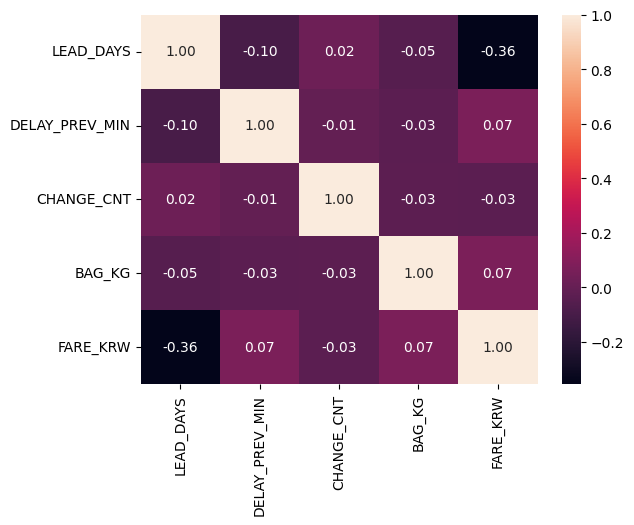

In [8]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

corr_df = df[['LEAD_DAYS', 'DELAY_PREV_MIN', 'CHANGE_CNT', 'BAG_KG', 'FARE_KRW']].corr()
sns.heatmap(corr_df, annot=True, fmt='.2f')
plt.show()

In [9]:
# (3) 정답을 입력하세요 — `정답03` 에 값만 넣고 실행하세요

정답03 = 'annot'

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

선택한 컬럼들만 골라 상관계수 행렬을 만든 뒤 히트맵으로 그립니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `.corr()`, `sns.heatmap`. 정답은 5글자이고 첫 글자는 `a` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

corr_df = df[['LEAD_DAYS', 'DELAY_PREV_MIN', 'CHANGE_CNT', 'BAG_KG', 'FARE_KRW']].corr()
sns.heatmap(corr_df, ann__=True, fmt='.2f')
plt.show()

정답03 = 'ann__'   # 빈칸에 넣은 단어
```

</details>

### **4. 그래프를 통해 노선 유형(ROUTE) 별 이전 편 지연(분)(DELAY_PREV_MIN)의 분포를 확인하려 합니다. 제시된 가이드에 맞춰 boxplot으로 시각화하세요.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(boxplot) · matplotlib(show) | 난이도: 쉬움 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- 대상 데이터프레임 : df
- seaborn 의 boxplot 으로 이전 편 지연(분)(DELAY_PREV_MIN) 컬럼의 분포를 그래프로 그리세요
- X축에는 노선 유형(ROUTE)를, Y축에는 이전 편 지연(분)(DELAY_PREV_MIN)를 표시하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 답안 셀에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 46041 (\N{HANGUL SYLLABLE DONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45224 (\N{HANGUL SYLLABLE NAM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50500 (\N{HANGUL SYLLABLE A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 44397 (\N{HANGUL SYLLABLE GUG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45236 (\N{HANGUL SYLLABLE NAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/l

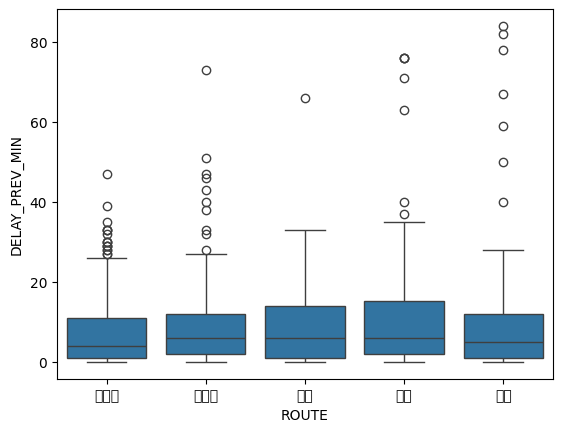

In [10]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

sns.boxplot(data=df, x='ROUTE', y='DELAY_PREV_MIN')
plt.show()

In [11]:
# (4) 정답을 입력하세요 — `정답04` 에 값만 넣고 실행하세요

정답04 = 'boxplot'

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

그룹별 분포와 이상치를 상자 그림으로 보여주는 그래프입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `sns.boxplot`. 정답은 7글자이고 첫 글자는 `b` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxp___(data=df, x='ROUTE', y='DELAY_PREV_MIN')
plt.show()

정답04 = 'boxp___'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 이전 편 지연(분)(DELAY_PREV_MIN) 컬럼의 이상치는 삭제하지 않고 정상 범위의 경계값으로 대체하고자 합니다.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, copy, clip, drop) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 2번 `df`
- 아래 가이드에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df
    - IQR 기준(K=2.0)으로 lower_fence, upper_fence 를 구하세요
    - DELAY_PREV_MIN 값이 두 fence 를 벗어나면 가장 가까운 fence 값으로 바꾸세요(행은 삭제하지 않음)
    - 식별자 컬럼 SERIAL_NO 를 삭제한 사본에 적용해 df_temp 에 보관하세요
- **[정답05]** 처리 후 DELAY_PREV_MIN 의 **최댓값**을 소수 둘째 자리까지 작성하세요
- 답안 : **[정답05]** 의 값만 답안 셀에 `정답05 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [12]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
# 1. 1사분위수(Q1), 3사분위수(Q3) 구하기
q1 = df['DELAY_PREV_MIN'].quantile(0.25)
q3 = df['DELAY_PREV_MIN'].quantile(0.75)

# 2. IQR 계산
iqr = q3 - q1

# 3. 이상치 경계값 계산 (K=2.0)
lower_fence = q1 - 2.0 * iqr
upper_fence = q3 + 2.0 * iqr

# 4. SERIAL_NO 컬럼을 삭제한 사본 생성
df_temp = df.drop(columns=['SERIAL_NO']).copy()

# 5. 이상치를 경계값으로 대체
df_temp['DELAY_PREV_MIN'] = df_temp['DELAY_PREV_MIN'].clip(
    lower=lower_fence,
    upper=upper_fence
)

# 6. 처리 후 최댓값 확인 (소수 둘째 자리)
print(round(df_temp['DELAY_PREV_MIN'].max(), 2))


34.0


In [ ]:
# (5) 정답을 입력하세요 — `정답05` 에 값만 넣고 실행하세요

정답05 = 34.0

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

값을 삭제하는 대신 범위 안으로 잘라 넣는 메서드를 쓰세요. 처리된 컬럼의 최댓값은 upper_fence 와 같거나 작습니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `clip`, `quantile`, `max`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
q1 = df['DELAY_PREV_MIN'].quantile(0.25)
q3 = df['DELAY_PREV_MIN'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 2.0 * iqr
upper_fence = q3 + 2.0 * iqr

df_temp = df.drop(columns=['SERIAL_NO']).copy()
df_temp['DELAY_PREV_MIN'] = df_temp['DELAY_PREV_MIN'].clip(lower=lower_fence, upper=upper_fence)

# [정답05] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
df_temp['____'].max()
```

</details>

### **6. 데이터에 결측치가 있을 경우 AI모델링의 성능이 저하될 수 있습니다. 다음 지침에 따라 결측치를 확인하고 처리하십시오.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(copy, fillna, mean, sum) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 5번 `df_temp`
- 대상 데이터프레임 : df_temp
- 다음 지침에 따라 결측치를 처리하고 검증하는데 오류가 발생하고 있습니다. 코드의 오류를 수정하세요
    - 수치형 컬럼(FARE_KRW, BAG_KG)의 결측치는 **평균** 으로 채우세요
    - 처리가 반영된 데이터프레임은 변수명 df_na 에 저장하고, 남은 결측치 개수를 출력하세요
- **[정답06]** 처리 후 df_na 의 FARE_KRW 평균을 소수 둘째 자리까지 기입하세요
- 답안 : **[정답06]** 의 값만 답안 셀에 `정답06 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [15]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

df_na = df_temp.copy()
df_na['FARE_KRW'] = df_na['FARE_KRW'].fillna(df_na['FARE_KRW'].mean())
df_na['BAG_KG'] = df_na['BAG_KG'].fillna(df_na['BAG_KG'].mean())
print(df_na.isnull().sum().sum())
round(df_na['FARE_KRW'].mean(),2)

0


np.float64(166557.02)

In [ ]:
# (6) 정답을 입력하세요 — `정답06` 에 값만 넣고 실행하세요

정답06 = 166557.02

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

결측치를 평균/최빈값으로 채우는 흐름을 점검하세요. 결측치를 채운 뒤 FARE_KRW 의 평균을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `mean`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
df_na = df_temp.copy()
df_na['FARE_KRW'] = df_na['FARE_KRW'].fillna(df_na['FARE_KRW'].mean())
df_na['BAG_KG'] = df_na['BAG_KG'].fillna(df_na['BAG_KG'].mean())
print(df_na.isnull().sum().sum())

# [정답06] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(df_na['____'].mean(), __)
```

</details>

### **7. 범주형 컬럼의 특성에 따라 인코딩 방식을 달리 적용하려 합니다. 다음 지침에 따라 인코딩하세요.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(copy, get_dummies) · scikit-learn(LabelEncoder, fit_transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 6번 `df_na`
- 다음 지침에 따라 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_na
    - 좌석 등급(CABIN) 는 sklearn **LabelEncoder** 로 정수 인코딩하세요
    - 나머지 문자열 컬럼 ROUTE, CHANNEL, MEMBER 은(는) get_dummies(drop_first=True)로 원-핫 인코딩하세요
    - 결과는 df_enc 에 저장하세요
- **[정답07]** 인코딩 후 df_enc 의 **전체 컬럼 개수**는 몇 개로 나타나나요?
- 답안 : **[정답07]** 의 값만 답안 셀에 `정답07 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [19]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
from sklearn.preprocessing import LabelEncoder

df_enc = df_na.copy()
le = LabelEncoder()
df_enc['CABIN'] = le.fit_transform(df_enc['CABIN'])
df_enc = pd.get_dummies(data=df_enc, columns=['ROUTE', 'CHANNEL', 'MEMBER'], drop_first=True)
df_enc.shape[1]

18

In [20]:
# (7) 정답을 입력하세요 — `정답07` 에 값만 넣고 실행하세요

정답07 = 18

<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

한 컬럼은 정수 라벨로, 나머지는 0/1 컬럼으로 바꿉니다. 인코딩이 끝난 데이터프레임의 컬럼 개수를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `LabelEncoder`, `fit_transform`, `pd.get_dummies`, `shape`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

from sklearn.preprocessing import LabelEncoder

df_enc = df_na.copy()
le = LabelEncoder()
df_enc['CABIN'] = le.fit_transform(df_enc['CABIN'])
df_enc = pd.get_dummies(data=df_enc, columns=['ROUTE', 'CHANNEL', 'MEMBER'], drop_first=True)

# [정답07] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
df_enc.shape[__]
```

</details>

### **8. 훈련과 검증 데이터셋을 분리하고, 검증 레이블의 분포를 확인하고자 합니다.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 보통 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 7번 `df_enc`
- 대상 데이터프레임 : df_enc
- 부가 매출(원)(ANCILLARY_KRW) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 대입하세요
- 데이터를 훈련 75 : 검증 25 로 분할합니다 (test_size=0.25)
- 결과를 재현할 수 있게 random_state 값을 7 로 지정하세요 / 분리 결과는 X_train, X_valid, y_train, y_valid 순서로 받으세요
- scikit-learn 의 train_test_split 함수를 활용하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답08]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답08]** 의 값만 답안 셀에 `정답08 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [22]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

from sklearn.model_selection import train_test_split

X = df_enc.drop('ANCILLARY_KRW', axis=1)
y = df_enc['ANCILLARY_KRW']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.25, random_state=7)

In [23]:
# (8) 정답을 입력하세요 — `정답08` 에 값만 넣고 실행하세요

정답08 = 'train_test_split'

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`. 정답은 16글자이고 첫 글자는 `t` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
from sklearn.model_selection import train_test_split

X = df_enc.drop('ANCILLARY_KRW', axis=1)
y = df_enc['ANCILLARY_KRW']

X_train, X_valid, y_train, y_valid = train_te________(X, y, test_size=0.25, random_state=7)

정답08 = 'train_te________'   # 빈칸에 넣은 단어
```

</details>

### **9. 변수들의 단위(범위) 차이가 모델에 영향을 주지 않도록 스케일링하는 코드가 있습니다. 빈칸을 채워 완성하세요.**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(StandardScaler, fit_transform, transform) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 훈련 데이터(X_train)는 변환 기준을 학습하면서 변환하고, 검증 데이터(X_valid)는 **학습된 기준으로 변환만** 합니다
- 사용할 스케일러 : StandardScaler
- **[정답09]** 스케일링 후 검증 데이터(X_valid)의 **최댓값**을 소수 둘째 자리까지 입력하세요
- 답안 : **[정답09]** 의 값만 답안 셀에 `정답09 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [27]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)
print(X_valid.max())

10.06364046956401


In [28]:
# (9) 정답을 입력하세요 — `정답09` 에 값만 넣고 실행하세요

정답09 = 10.06

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 이미 학습한 기준으로 변환만 하는 메서드입니다(검증 데이터에 사용). 변환된 검증 데이터 전체에서 최댓값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `StandardScaler`, `fit_transform`, `transform`, `np.max`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.max(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 부가 매출(원)(ANCILLARY_KRW)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. LinearRegression와(과) DecisionTree는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(LinearRegression, fit, DecisionTreeRegressor) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- LinearRegression 모델을 아래와 같이 만들어 `lin` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : 지정하지 않음(기본값)
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- DecisionTree 모델을 아래와 같이 만들어 `dt` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : max_depth=3, min_samples_leaf=5
    - 난수 시드(random_state) : 1
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `lin`(LinearRegression) 의 절편(`intercept_`)을 소수점 둘째 자리까지 작성하세요
- 답안 : **[정답10]** 의 값만 답안 셀에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [32]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
# 1. 필요한 라이브러리 불러오기
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

# 2. LinearRegression 모델 생성
lin = LinearRegression()

# 3. LinearRegression 모델 학습
lin.fit(X_train, y_train)

# 4. DecisionTree 모델 생성
dt = DecisionTreeRegressor(
    max_depth=3,
    min_samples_leaf=5,
    random_state=1
)

# 5. DecisionTree 모델 학습
dt.fit(X_train, y_train)

# 6. LinearRegression 절편 확인
print(round(lin.intercept_, 2))

46045.39


In [ ]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)



In [33]:
# (10) 정답을 입력하세요 — `정답10` 에 값만 넣고 실행하세요

정답10 = 46045.39

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 선형 모델은 학습 후 intercept_ 속성에 절편을 저장합니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `LinearRegression`, `fit`, `DecisionTreeRegressor`, `intercept_`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.linear_model import LinearRegression

lin = LinearRegression()
lin.fit(X_train, y_train)

from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(max_depth=3, min_samples_leaf=5, random_state=1)
dt.fit(X_train, y_train)

# [정답10] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(lin.intercept_, __)
```

</details>

### **11. 선형회귀 모델의 계수 크기로 어떤 변수가 예측에 큰 영향을 주는지 해석할 계획입니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(sort_values, Series, columns) · NumPy(abs) · scikit-learn(coef_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 8번 `X` · 10번 `lin`
- 학습된 lin 의 계수(`coef_`)의 **절댓값**을 변수명(X.columns)과 매핑한 Series 로 만들어 내림차순 정렬한 뒤 `coef_s` 에 저장하세요
- **[정답11]** 계수 절댓값이 **가장 큰 변수명**을 쓰세요
- 답안 : **[정답11]** 의 값만 답안 셀에 `정답11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [37]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
import numpy as np
import pandas as pd

# 1. 회귀계수의 절댓값 구하기
coef = np.abs(lin.coef_)

# 2. 변수명과 계수 연결하기
coef_s = pd.Series(coef, index=X.columns)

# 3. 계수 절댓값을 기준으로 내림차순 정렬
coef_s = coef_s.sort_values(ascending=False)

# 4. 결과 확인
print(coef_s)

LEAD_DAYS         16206.036019
PAST_FLIGHTS       8886.786227
CHANGE_CNT         4419.635173
FARE_KRW           3019.019736
CABIN              2284.425354
CHANNEL_웹           693.924789
ROUTE_일본            391.909529
ROUTE_동남아           308.338995
CHANNEL_앱           281.457170
BAG_KG              236.486276
MEMBER_일반           229.539034
DELAY_PREV_MIN      206.345493
MEMBER_최우수          138.544129
ROUTE_미주             92.317099
MILES                79.018413
ROUTE_유럽             47.462070
CHANNEL_제휴            0.070195
dtype: float64


In [38]:
# (11) 정답을 입력하세요 — `정답11` 에 값만 넣고 실행하세요

정답11 = 'LEAD_DAYS'

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

학습된 계수의 절댓값을 변수명과 묶어 정렬합니다. coef_s 의 첫 번째 인덱스를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `coef_`, `np.abs`, `sort_values`, `index`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd
import numpy as np

coef_s = pd.Series(np.abs(lin.coef_), index=X.columns).sort_values(ascending=False)

# [정답11] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
coef_s.index[__]
```

</details>

### **12. 앞서 학습시킨 LinearRegression와(과) DecisionTree 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, mean_absolute_error) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `dt`, `lin`
- 아래 안내대로 각 모델의 MAE(평균절대오차) 를 산출하려는데 실행 중 예외가 발생합니다. 코드의 오류를 바로잡으세요
    - 앞서 학습시킨 lin 와 dt 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 MAE(평균절대오차) 값을 각각 linreg_score, dt_score 변수에 저장하고 출력하세요
- **[정답12]** 두 모델의 MAE(평균절대오차) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (LinearRegression / DecisionTree 중 하나)
- 답안 : **[정답12]** 의 값만 답안 셀에 `정답12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [39]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.metrics import mean_absolute_error

y_pred_linreg = lin.predict(X_valid)
y_pred_dt = dt.predict(X_valid)

linreg_score = mean_absolute_error(y_pred_linreg, y_valid)
dt_score = mean_absolute_error(y_valid, y_pred_dt)
print(linreg_score, dt_score)

7532.403545219481 9281.40560734313


In [41]:
# (12) 정답을 입력하세요 — `정답12` 에 값만 넣고 실행하세요

정답12 = 'LinearRegression'

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

MAE(평균절대오차) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 작을수록 우수한 지표입니다. 두 점수를 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.metrics import mean_absolute_error

y_pred_linreg = lin.predict(X_valid)
y_pred_dt = dt.predict(X_valid)

linreg_score = mean_absolute_error(y_valid, y_pred_linreg)
dt_score = mean_absolute_error(y_valid, y_pred_dt)
print(linreg_score, dt_score)

# [정답12] 실행한 결과를 입력하세요
print(linreg_score, dt_score)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [42]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(7)

### **13. 부가 매출(원)(ANCILLARY_KRW)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 가이드에 맞춰 신경망을 구성한 뒤 학습까지 진행하세요.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit) | 난이도: 보통 | 예상 시간: 13분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- tensorflow framework 를 사용하세요
- 은닉층 구성 : Dense × 2 (노드 [16, 8]), activation='selu'
- 비율 0.3 의 Dropout 층을 첫 번째 은닉층 뒤에 넣으세요 / 각 Dense 층 뒤에 BatchNormalization 층을 추가하세요
- val_loss 가 14 epoch 연속 좋아지지 않으면 멈추는 EarlyStopping(restore_best_weights=True)을 estop 변수에 담으세요
- 마지막 Dense 층 : 노드 1개 · 활성화 함수 'linear'
- optimizer 는 문자열이 아니라 Adam(learning_rate=0.0005) 객체로 지정하고, loss 는 mse, metrics 는 [mae] 로 지정해서 모델을 컴파일하세요
- batch_size 는 16, epochs 는 20 로 학습하고 학습정보는 history 변수에 저장하세요 (검증은 훈련 데이터의 20% 를 쓰는 validation_split=0.2 로 지정)
- 안내하지 않은 파라미터는 지정하지 마세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답13]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답13]** 의 값만 답안 셀에 `정답13 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [43]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

model = Sequential([
    Dense(16, activation='selu', input_dim=X_train.shape[1]),
    BatchNormalization(),
    Dropout(0.3),
    Dense(8, activation='selu'),
    BatchNormalization(),
    Dense(1, activation='linear')
])

estop = EarlyStopping(monitor='val_loss', patience=14, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer=Adam(learning_rate=0.0005), loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train,
                    epochs=20, batch_size=16,
                    validation_split=0.2,
                    callbacks=cb_list)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 2611514880.0000 - mae: 45901.6094 - val_loss: 2669899520.0000 - val_mae: 46620.4531
Epoch 2/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 2611504384.0000 - mae: 45901.5664 - val_loss: 2669888768.0000 - val_mae: 46620.3789
Epoch 3/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 2611495936.0000 - mae: 45901.5039 - val_loss: 2669879040.0000 - val_mae: 46620.3203
Epoch 4/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2611483648.0000 - mae: 45901.4453 - val_loss: 2669867776.0000 - val_mae: 46620.2500
Epoch 5/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2611474176.0000 - mae: 45901.3828 - val_loss: 2669855232.0000 - val_mae: 46620.1758
Epoch 6/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2611463424.0000 - mae: 45901.3242 - val_loss: 2669843456.0000 - val_mae: 46620.1289
Epoch 7/20
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 2611447552.0000 - mae: 45901.2578 - val_loss: 2669831936.0000 - val_mae: 46620.1016
Epoch

In [44]:
# (13) 정답을 입력하세요 — `정답13` 에 값만 넣고 실행하세요

정답13 = 'EarlyStopping'

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

가이드의 모델 구조·학습 조건을 코드의 각 줄과 대응시켜 보세요. 검증 손실이 더 이상 좋아지지 않으면 학습을 일찍 멈추는 콜백입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`. 정답은 13글자이고 첫 글자는 `E` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
model = Sequential([
    Dense(16, activation='selu', input_dim=X_train.shape[1]),
    BatchNormalization(),
    Dropout(0.3),
    Dense(8, activation='selu'),
    BatchNormalization(),
    Dense(1, activation='linear')
])

estop = EarlySt______(monitor='val_loss', patience=14, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer=Adam(learning_rate=0.0005), loss='mse', metrics=['mae'])

history = model.fit(X_train, y_train,
                    epochs=20, batch_size=16,
                    validation_split=0.2,
                    callbacks=cb_list)

정답13 = 'EarlySt______'   # 빈칸에 넣은 단어
```

</details>

### **14. 학습이 끝난 모델의 최종 성능을 검증 데이터로 한 번 더 확인하려 합니다.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: TensorFlow(Keras)(evaluate) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 13번 `model`
- 학습된 `model` 의 `evaluate` 로 검증 데이터(X_valid, y_valid)의 성능을 계산하세요 (verbose=0)
    - 반환되는 값은 loss 와 compile 에서 지정한 metrics(mae) 순서입니다. 각각 `loss, mae` 변수에 보관하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답14]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답14]** 의 값만 답안 셀에 `정답14 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [46]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

loss, mae = model.evaluate(X_valid, y_valid, verbose=0)

In [48]:
# (14) 정답을 입력하세요 — `정답14` 에 값만 넣고 실행하세요

정답14 = 'verbose'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

학습된 모델에 검증 데이터를 넣어 손실과 지표를 한 번에 구합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `model.evaluate`. 정답은 7글자이고 첫 글자는 `v` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
loss, mae = model.evaluate(X_valid, y_valid, verb___=0)

정답14 = 'verb___'   # 빈칸에 넣은 단어
```

</details>

### **모든 문항이 완료되었습니다. 수고하셨습니다.**
### 답안을 저장한 뒤 제출해 주시기 바랍니다.